# Testing inference: how long must the trigger be?

Retrieval is cued by only a *fragment* of the stored motif. This notebook measures the
minimal **trigger duration** `N_trigger_time` (in ms) such that showing the last
`N_trigger_time` bins of the spiking-motif (SM) window suffices for the network to re-emit
the full pattern in the evoked window. The fragment is aligned on the end of the trigger
window, where the replay starts, because the readout is only trained on complete SM
windows; the first `num_delay - N_trigger_time` bins of the trigger window prolong the
spontaneous activity. It probes the temporal completeness property of the memory
(pattern completion along time).

## Notebook summary

### Pipeline
1. Load the trained `<datetag>_vanilla.pth` (same weights as notebooks 11/13/14 - no
    retraining here).
2. Single trial with a partial trigger (`N_trigger_time = int(0.975 * num_delay)` = 39 ms) -> F1 + raster.
3. Scan `N_trigger_time = 1 .. num_delay` x `N_cv=11` seeded repetitions
    (`get_scores_fraction`) -> per-length F1 (mean, 5%-95% beta quantiles), cached as
    `<datetag>_trigger_time.npz` (+ `.lock`); plot `trigger_time_score.pdf`.
4. Theory: ignition model of the replay (`get_f1_ignition`, with a fraction
    `N_trigger_time / num_delay` of the window shown and a deficit lasting
    `num_delay - N_trigger_time` steps), overlaid on `trigger_time_score.pdf`.

### Main outputs
- cache `../cached_data/<datetag>_trigger_time.npz` (arrays `N_trigger_times`, `scores_np`);
- figures `trigger_time.pdf` (raster) and `trigger_time_score.pdf` (F1 vs trigger length).


In [1]:
# Shared helpers from mnesis_boilerplate; model/algorithm from mnesis_chains.

from mnesis_boilerplate import torch, np, plt, splt, data_cache, figpath, RECOMPUTE, Params
from mnesis_boilerplate import printfig, get_scores, get_f1score, get_beta_errorbar, trange
from mnesis_boilerplate import get_f1_ignition
from mnesis_chains import load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


In [2]:
# Load the trained vanilla readout; the frozen pattern is the same (same seed).
opt = Params() # type: ignore
model_filename = data_cache / f"{opt.datetag}_vanilla.pth"
hd = load(opt, model_filename)
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


In [3]:
# Full production parameters (see notebook 11's Parameters table).
opt

Params(datetag='2026-09-07', N_neuron=1024, num_delay=41, N_pattern=16, N_time=1000, N_pretime=50, p_A=0.00016, p_flip=0.01, seed=2026, lif_beta=0.7, lif_threshold=0.75, learn_beta=False, learn_threshold=False, do_pinv=True, do_deconv=True, num_epochs=256, num_warmup_epochs=16, base_lr=0.04, final_lr=0.0004, delta1=0.003, delta2=1e-05, dropout=0.6, alpha_surrogate=5.0, surrogate_name='FastSigmoid', loss_name='SpikeF1scoreLoss', reset_mechanism='zero', optimizer='adadelta', verbose=False, fig_width=15.92, phi=1.61803, fig_height=9.839125356142963, N_time_show=1000, N_neuron_show=1024, i_pattern=0, N_scan=14, N_cv=11)

In [4]:
# lin (41984 -> 1024 delay-tap readout) + dropout + Leaky; eval() for deterministic probes.
hd.net.eval()

Sequential(
  (lin): Linear(in_features=41984, out_features=1024, bias=False)
  (dropout): Dropout(p=0.6, inplace=False)
  (lif): Leaky()
)

## Retrieval from a partial trigger

Single trial: `N_trigger_time = int(0.975 * num_delay)` (39 ms instead of 41): only the last
39 bins of the SM window are shown, the first 2 carry spontaneous activity. Scored on the
full evoked window against the complete target.

In [5]:
# Partial trigger: get_input_spikes shows only the last N_trigger_time bins of the SM window.

with torch.no_grad():
    target = hd.pattern_object.frozen_target # noise-free reference, scored against
    cue = hd.pattern_object(seed=hd.opt.seed) # seeded noisy realisation, provides the trigger
    N_trigger_time = int(hd.opt.num_delay*.975)
    target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=cue, N_trigger_time=N_trigger_time, seed=hd.opt.seed)
    _, _, spikes = hd.forward_pass(input_spikes)
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target[:, :, hd.opt.num_delay:]
    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.926	 recall = 0.825	 f1_score = 0.873 


### Raster of the partial-trigger trial

Legend as in notebook 11 (green `x` trigger, red `o` target, blue `+` evoked; dashed
verticals at `N_pretime` and `N_pretime + num_delay`): the green trigger only covers the
end of the trigger window, the bins before it carry spontaneous activity.

Saving as ../figures/trigger_time.pdf
Saving as ../figures/trigger_time.png
Saving as ../figures/trigger_time.svg


(torch.Size([16, 1024, 1100]), 144.0, 140.0)

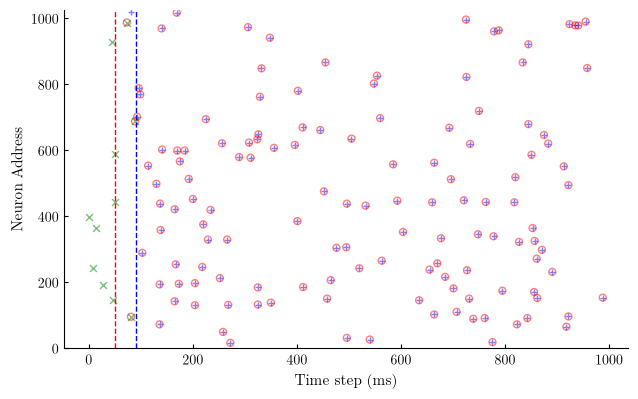

In [6]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'trigger_time', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Sweep: F1 as a function of the trigger duration

`get_scores_fraction`: one forward pass per `N_trigger_time` in `1 .. num_delay`,
scoring the evoked window with `get_f1score`. The curve reveals the *critical trigger
length* at which retrieval emerges (and the floor, f1 ~ 0, for spontaneous-only cues).
Cached as `<datetag>_trigger_time.npz` under the `.lock` protocol.

In [7]:
np.arange(1, hd.opt.num_delay+1)

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41])

In [8]:
# One cue realisation per repetition (seeded nb 20-style), reduced to the last
# N_trigger_time bins of its SM window and scored against the clean frozen_target; the cache is saved after every
# trigger length so an interrupted run can resume from the file.

def get_scores_fraction(N_cv=opt.N_cv):
    N_trigger_times = np.arange(1, hd.opt.num_delay+1)
    scores_np = np.zeros((N_trigger_times.size, N_cv))
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    seed = hd.opt.seed # base seed, incremented per repetition (nb 20 convention)
    for i_trigger_time in trange(N_trigger_times.size):
        N_trigger_time = N_trigger_times[i_trigger_time]
        for i_cv in range(N_cv):
            with torch.no_grad():
                target_ = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=target_, N_trigger_time=N_trigger_time, seed=seed)
                _, _, spikes = hd.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]

                scores_np[i_trigger_time, i_cv] = get_f1score(spikes_evoked, target_evoked)
                seed += 1

        np.savez(npy_filename, N_trigger_times=N_trigger_times, scores_np=scores_np) # incremental save

    return N_trigger_times, scores_np

# RECOMPUTE = True # overwriting the default value
npy_filename = data_cache / f"{hd.opt.datetag}_trigger_time.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    N_trigger_times = data['N_trigger_times']
    scores_np = data['scores_np']
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except FileNotFoundError:
    if not lock_filename.exists():
        print(f"Score file not found: {npy_filename}, evaluating the score.")
        lock_filename.touch(exist_ok=True)
         ##################
        N_trigger_times, scores_np = get_scores_fraction()
         ##################
        np.savez(npy_filename, N_trigger_times=N_trigger_times, scores_np=scores_np)
        lock_filename.unlink(missing_ok=True)
    else:
        print(f"Score file is locked: {lock_filename}, passing.")

Score file not found: ../cached_data/2026-09-07_trigger_time.npz, evaluating the score.


100%|██████████| 41/41 [08:24<00:00, 12.29s/it]


## Expected F1 from theory

The ignition model of notebook 14 (`get_f1_ignition`) applies to a trigger reduced to the
last $L$ bins of its window. A spike supporting the first evoked spikes is present with probability

$$q = \frac{L}{D}\,\big(1 - p_\mathrm{flip}\,(1 - p_A)\big),$$

where $D$ is the width of the spiking-motif window, $p_\mathrm{flip}$ the bit-flip probability
of the cue and $p_A$ the firing probability of the motif. A spike of the motif is emitted if at
least $\lceil \vartheta K \rceil$ of its $K$ supporting spikes are present, with $\vartheta$ the
firing threshold and $K$ a Poisson variable of mean $\lambda = p_A N D$ ($N$ neurons), that is
with probability

$$\Phi(q) = \sum_{K \geq 1} \frac{e^{-\lambda} \lambda^K}{K!} \sum_{k = \lceil \vartheta K \rceil}^{K} \binom{K}{k}\, q^k (1 - q)^{K - k},$$

Unlike scattered flips, the partial trigger leaves a gap $[0, D - L)$ at the start of the window,
filled with spontaneous activity whose spikes fall on near-zero weights. The first evoked step
sees a fraction $L/D$ of its supporting spikes, and the gap then slides out of the window: the
deficit lasts the $D - L$ steps that follow the trigger. As a heuristic, the replay must then emit
without any failure the spikes evoked during this deficit, a Poisson number of mean
$p_A N (D - L)$, so that the ignition probability is

$$R(L) = \Phi(q)\, \exp\big(-p_A N (D - L)\, (1 - \Phi(q))\big),$$

and, as in notebook 14, $F_1 = 2\, R\, r_0 / (1 + R\, r_0 / \pi_0)$, with $\pi_0$ and $r_0$ the
precision and recall with the full trigger ($L = D$). The threshold is the LIF threshold of the
network, not a fitted value. Counting a single missed spike as a failure of the whole replay,
the heuristic underestimates the F1 score just below the transition.

| symbol | name in the code | default value | role |
|---|---|---|---|
| $L$ | `N_trigger_time` | swept from 1 to 41 bins (1 to 41 ms) | trigger duration, shown at the end of the window |
| $D$ | `num_delay` | 41 bins (41 ms) | width of the spiking-motif window |
| $N$ | `N_neuron` | 1024 | number of neurons |
| $p_\mathrm{flip}$ | `p_flip` | 0.01 | bit-flip probability of the cue |
| $p_A$ | `p_A` | $1.6 \times 10^{-4}$ per 1 ms bin (0.16 Hz) | firing probability of the motif |
| $\vartheta$ | `lif_threshold` | 0.75 | firing threshold, relative to the membrane potential reached on the motif |
| $\lambda$ | `p_A * N_neuron * num_delay` | 6.72 | mean number of spikes supporting a spike of the motif |
| $q$ | `fraction * (1 - p_flip * (1 - p_A))` | - | probability that a supporting spike is present in the trigger |
| $\Phi$ | - | - | probability that a spike of the motif is emitted |
| $R$ | - | - | probability that the replay of a motif ignites |
| $\pi_0$, $r_0$ | `precision_0`, `recall_0` | measured with $L = D$ | precision and recall with the full trigger |

The cell below measures $\pi_0$ and $r_0$ with the first repetition of the sweep protocol (same
seed, full trigger), evaluates the ignition model, and reports its RMS error on the sweep. In the
score figure, the dashed black line is this $F_1$.

In [9]:
# Precision and recall of the replay with the full trigger (first repetition of the sweep
# protocol, same seed): the only measured inputs of the ignition model.

with torch.no_grad():
    target_ = hd.pattern_object(seed=opt.seed)
    _, _, spikes = hd.forward_pass(hd.get_input_spikes(target=target_, N_trigger_time=opt.num_delay, seed=opt.seed))
    spikes_evoked = spikes[:, :, (opt.N_pretime+opt.num_delay):(opt.N_time+opt.N_pretime)]
    target_evoked = hd.pattern_object.frozen_target[:, :, opt.num_delay:]
    precision_0, recall_0, f1_score_0 = [score.item() for score in get_scores(spikes_evoked, target_evoked)]
print(f'full trigger: precision = {precision_0:.3f}\t recall = {recall_0:.3f}\t f1_score = {f1_score_0:.3f}')

theory_dict = dict(p_flip=opt.p_flip, p_A=opt.p_A, N_neuron=opt.N_neuron, num_delay=opt.num_delay,
                   lif_threshold=opt.lif_threshold, precision_0=precision_0, recall_0=recall_0)
# partial trigger: a fraction L / D of the window is shown, and the gap stays in it for D - L steps
N_trigger_times_theory = np.linspace(1, opt.num_delay, 201)
f1_ignition_theory = get_f1_ignition(fraction=N_trigger_times_theory/opt.num_delay,
                                     deficit_steps=opt.num_delay-N_trigger_times_theory, **theory_dict)
if not lock_filename.exists():
    f1_ignition_scan = get_f1_ignition(fraction=N_trigger_times/opt.num_delay, deficit_steps=opt.num_delay-N_trigger_times, **theory_dict)
    rmse = np.sqrt(np.mean((f1_ignition_scan - scores_np.mean(axis=1))**2))
    print(f'RMS error of the ignition model on the sweep = {rmse:.3f}')

full trigger: precision = 0.877	 recall = 0.825	 f1_score = 0.850
RMS error of the ignition model on the sweep = 0.292


Saving as ../figures/trigger_time_score.pdf
Saving as ../figures/trigger_time_score.png
Saving as ../figures/trigger_time_score.svg


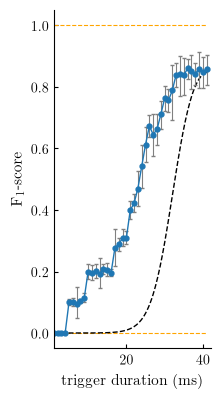

In [10]:
# $F_1$ vs trigger duration (ms), mean and 5%-95% quantiles of a beta fit over N_cv realisations; orange guides at 0 and 1;
# dashed: ignition model.

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], N_trigger_times[0], N_trigger_times[-1], 'orange', ls='--', lw=0.8)
    ax.plot(N_trigger_times_theory, f1_ignition_theory, color='k', ls='--')
    mean, yerr = get_beta_errorbar(scores_np)
    ax.errorbar(N_trigger_times, mean, yerr=yerr, fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0)
    ax.set_xlabel(r"trigger duration (ms)")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(N_trigger_times[0], N_trigger_times[-1]+1)
    ax.set_ylim(-0.05, 1.05)

    printfig(fig, 'trigger_time_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)
